# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import joblib
import warnings
warnings.filterwarnings("ignore")



# Load dataset

In [2]:
df=pd.read_csv(r"C:\Users\ADMIN\OneDrive\Desktop\Auspify_ML_Internship\Data\Dataset.csv")
print("Dataset Shape:",df.shape)
df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Missing value:\n",df.isnull().sum())
print("\nUnique value per column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")


Missing value:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Unique value per column:
show_id: 8790
type: 2
title: 8787
director: 4528
country: 86
date_added: 1713
release_year: 74
rating: 14
duration: 220
listed_in: 513


In [4]:
print("Rating count:",df["rating"].value_counts())
print("\nRating percentage:",(df["rating"].value_counts(normalize=True)*100).round(2))

Rating count: rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Rating percentage: rating
TV-MA       36.46
TV-14       24.54
TV-PG        9.80
R            9.09
PG-13        5.57
TV-Y7        3.79
TV-Y         3.48
PG           3.27
TV-G         2.50
NR           0.90
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
Name: proportion, dtype: float64


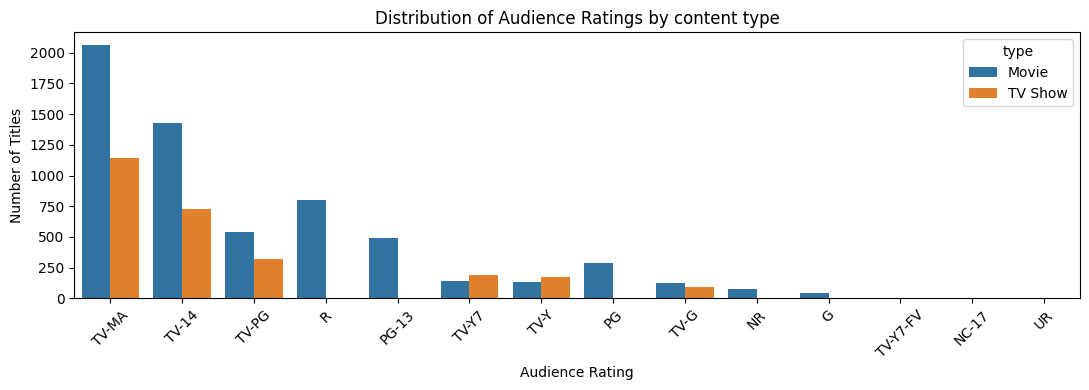

In [5]:
plt.figure(figsize=(11,4))
sns.countplot(
    data=df,
    x="rating",
    order=df["rating"].value_counts().index,hue="type"
)
plt.title("Distribution of Audience Ratings by content type")
plt.xlabel("Audience Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
rating_counts=df["rating"].value_counts()
valid_ratings=rating_counts[rating_counts>=10].index
df_clean=df[df["rating"].isin(valid_ratings)].copy()
print("Original rows:",len(df))
print("Cleaned rows:",len(df_clean))
print("Remaining rating classes:", df_clean["rating"].nunique())

Original rows: 8790
Cleaned rows: 8778
Remaining rating classes: 11


In [7]:
# Extract numeric value from duration (e.g., '90 min' -> 90, '1 Season' -> 1)
df_clean["duration_num"] = df_clean["duration"].str.extract(r"(\d+)").astype(float)

# Keep top 15 countries and group the rest into 'Other' to avoid noisy sparse columns
top_countries = df_clean["country"].value_counts().head(15).index
df_clean["country_clean"] = np.where(
    df_clean["country"].isin(top_countries),
    df_clean["country"],
    "Other"
)

print("Unique countries after grouping:", df_clean["country_clean"].nunique())
df_clean[["type", "country_clean", "release_year", "duration_num", "listed_in"]].head()

Unique countries after grouping: 16


,type,country_clean,release_year,duration_num,listed_in
0,Movie,United States,2020,90.0,Documentaries
1,TV Show,France,2021,1.0,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,United States,2021,1.0,"TV Dramas, TV Horror, TV Mysteries"
3,Movie,Other,2021,91.0,"Children & Family Movies, Comedies"
4,Movie,United States,1993,125.0,"Dramas, Independent Movies, International Movies"


In [ ]:
X = df_clean[["type", "country_clean", "release_year", "duration_num", "listed_in"]]
y = df_clean["rating"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nTraining target classes:", y_train.nunique())
print("Testing target classes:", y_test.nunique())

X_train shape: (7022, 5)
X_test shape: (1756, 5)

Training target classes: 11
Testing target classes: 11


In [9]:
# Parse comma-separated genres
train_genres = [[g.strip() for g in item.split(",")] for item in X_train["listed_in"]]
test_genres = [[g.strip() for g in item.split(",")] for item in X_test["listed_in"]]

mlb = MultiLabelBinarizer()
genre_train_encoded = mlb.fit_transform(train_genres)
genre_test_encoded = mlb.transform(test_genres)

genre_train_df = pd.DataFrame(genre_train_encoded, columns=mlb.classes_, index=X_train.index)
genre_test_df = pd.DataFrame(genre_test_encoded, columns=mlb.classes_, index=X_test.index)

print("Genre train shape:", genre_train_df.shape)
print("Genre test shape:", genre_test_df.shape)

Genre train shape: (7022, 42)
Genre test shape: (1756, 42)


In [10]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

cat_train_encoded = encoder.fit_transform(X_train[["type", "country_clean"]])
cat_test_encoded = encoder.transform(X_test[["type", "country_clean"]])

cat_cols = encoder.get_feature_names_out(["type", "country_clean"])

cat_train_df = pd.DataFrame(cat_train_encoded, columns=cat_cols, index=X_train.index)
cat_test_df = pd.DataFrame(cat_test_encoded, columns=cat_cols, index=X_test.index)

print("Categorical train shape:", cat_train_df.shape)
print("Categorical test shape:", cat_test_df.shape)

Categorical train shape: (7022, 18)
Categorical test shape: (1756, 18)
